# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [1]:
# Write your code here.
import pandas as pd
flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")

Display the first five rows of the DataFrame.


In [2]:
# Write your code here.
print(flights.head())

           airline    origin_city destination_city  distance_miles  \
0  Alaska Airlines  Anchorage, AK      Chicago, IL            2846   
1  Alaska Airlines  Anchorage, AK      Cordova, AK             160   
2  Alaska Airlines  Anchorage, AK    Fairbanks, AK             261   
3  Alaska Airlines  Anchorage, AK       Juneau, AK             571   
4  Alaska Airlines  Anchorage, AK       Juneau, AK             571   

   arrival_delay_minutes  
0                     65  
1                     -1  
2                    -18  
3                    -21  
4                    -14  


Display the last five rows of the DataFrame.


In [3]:
# Write your code here.
print(flights.tail())

              airline                     origin_city destination_city  \
4995  United Airlines  West Palm Beach/Palm Beach, FL      Chicago, IL   
4996  United Airlines  West Palm Beach/Palm Beach, FL      Houston, TX   
4997  United Airlines  West Palm Beach/Palm Beach, FL      Houston, TX   
4998  United Airlines  West Palm Beach/Palm Beach, FL       Newark, NJ   
4999  United Airlines  West Palm Beach/Palm Beach, FL       Newark, NJ   

      distance_miles  arrival_delay_minutes  
4995            1144                      0  
4996             956                    -22  
4997             956                    -29  
4998            1024                    -26  
4999            1024                      7  


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [4]:
# Write your code here.
flights.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   airline                5000 non-null   str  
 1   origin_city            5000 non-null   str  
 2   destination_city       5000 non-null   str  
 3   distance_miles         5000 non-null   int64
 4   arrival_delay_minutes  5000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 399.5 KB


**How many observations are in the DataFrame?**

Your answer: 5000


Count the missing values in every feature.


In [5]:
# Write your code here.
flights.isnull().sum()

airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` | str | categorical | 0 |
| `origin_city` | str | categorical | 0 |
| `destination_city` | str | categorical | 0 |
| `distance_miles` | int64 | quantitatative | 0 |
| `arrival_delay_minutes` | int64 | quantitative | 0 |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [6]:
# Write your code here.
destination_counts = flights["destination_city"].value_counts()
print(destination_counts.to_string())

destination_city
Chicago, IL                       296
Atlanta, GA                       222
Dallas/Fort Worth, TX             210
Denver, CO                        209
Washington, DC                    165
Phoenix, AZ                       149
Seattle, WA                       148
Charlotte, NC                     146
New York, NY                      145
Los Angeles, CA                   131
Houston, TX                       125
Las Vegas, NV                     124
San Francisco, CA                 112
Boston, MA                        107
Detroit, MI                        94
Orlando, FL                        93
Minneapolis, MN                    90
Philadelphia, PA                   90
Miami, FL                          86
Nashville, TN                      78
Newark, NJ                         76
Austin, TX                         73
Baltimore, MD                      68
San Diego, CA                      64
Salt Lake City, UT                 61
Sacramento, CA                   

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


Text(0.5, 0, 'City')

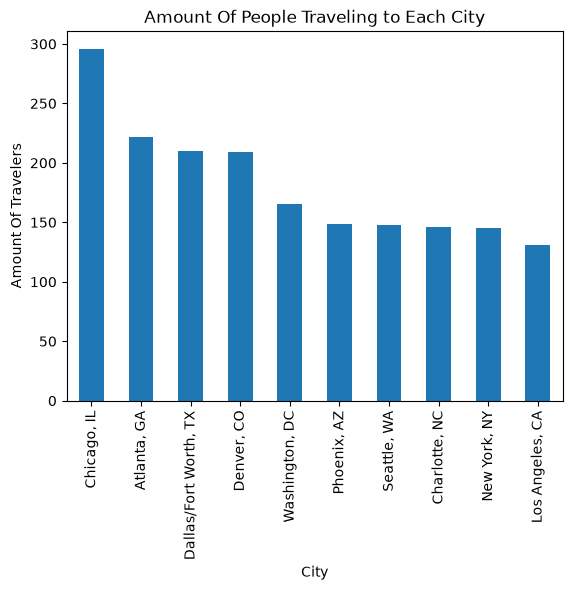

In [7]:
# Write your code here.
import matplotlib.pyplot as plt
destination_counts.head(10).plot(kind='bar')
plt.title("Amount Of People Traveling to Each City")
plt.ylabel("Amount Of Travelers")
plt.xlabel("City")

**Which destination city is most common in the sample?**

Your answer: Chicago, IL


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


Text(0.5, 0, 'Arrival Delay (in Minutes)')

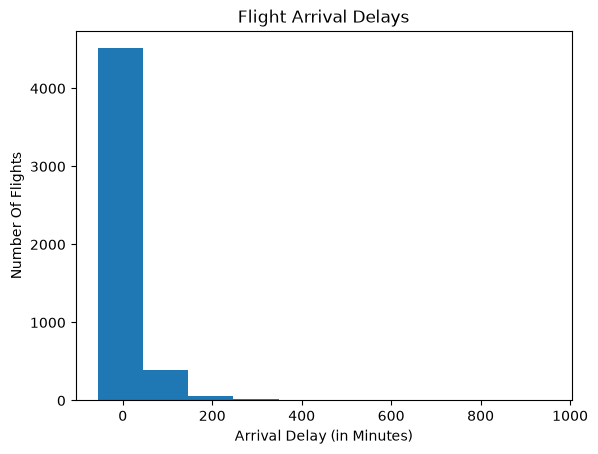

In [8]:
# Write your code here.
flights["arrival_delay_minutes"].plot(kind="hist")
plt.title("Flight Arrival Delays")
plt.ylabel("Number Of Flights")
plt.xlabel("Arrival Delay (in Minutes)")

**Approximately what arrival-delay value appears most common?**

Your answer: 0


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer: The histogram graph of the dataset ranges from slightly below 0 (potentially around -50) to 1000


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer: Heavily skewed with most of the data residing on the left and the "tail" extending to the right


Display a numerical summary of `arrival_delay_minutes`.


In [9]:
# Write your code here.
flights["arrival_delay_minutes"].describe()

count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [10]:
# Write your code here.
flights["arrival_delay_minutes"].mode()

0   -8
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer: Using .mode() gave 2 values (0 and -8) and due to the large bin size, both would be included in the first bin centered around the 0 value


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer: The max of 953 and the min of -55 were "close" to the range estimated (-50 to 1000) but due to the large bin size, it would be extremely difficult to find these exact values from that graph. The only reason I even knew negative values were in the dataset was due to the explanation of the data at the top of this section as well as looking at the general bin size, and the 1000 was assumed by the number being included at the end of the graph even though there wasn't a visible indicator of data being at the end.

**Is the mean greater than, less than, or approximately equal to the median?**

Your answer: The mean (6.098800) is greater than the median (-6.000000)


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer: When a mean is greater than the median it indicates the graph is right skewed, meaning most of the data is clumped on the left side and the tail extends out to the right (which matches the graph)


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


Text(0.5, 0, 'Arrival Delay (in Minutes)')

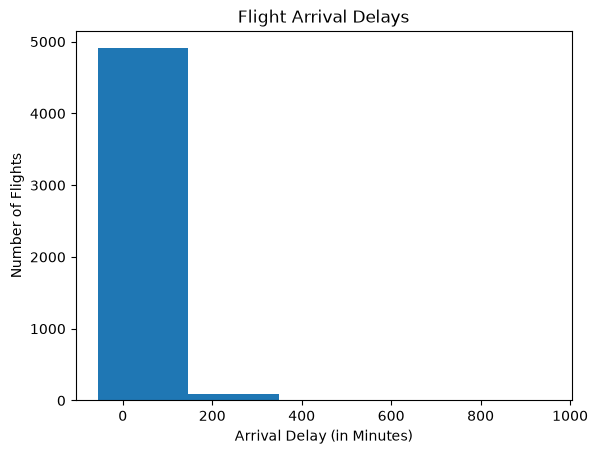

In [11]:
# Write your code here.
flights["arrival_delay_minutes"].plot(kind="hist", bins=5)
plt.title("Flight Arrival Delays")
plt.ylabel("Number of Flights")
plt.xlabel("Arrival Delay (in Minutes)")

Re-create the arrival-delay histogram using exactly 25 bins.


Text(0.5, 0, 'Flight Delay (in Minutes)')

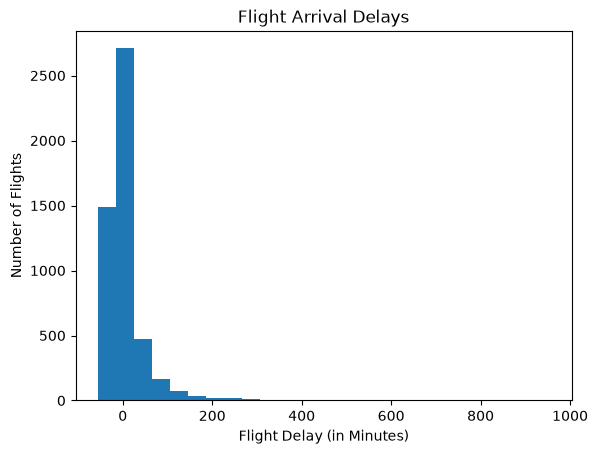

In [12]:
# Write your code here.
flights["arrival_delay_minutes"].plot(kind="hist", bins=25)
plt.title("Flight Arrival Delays")
plt.ylabel("Number of Flights")
plt.xlabel("Flight Delay (in Minutes)")

**What changed when the number of bins was reduced to 5?**

Your answer: When the bin size was reduced to 5, the data was "squished" even more into larger bins which makes seeing any differentiation between data even harder as a large majority of the data is within the very first bin.

**What changed when the number of bins was increased to 25?**

Your answer: Increasing the number of bins to 25 made the bin sizes much smaller.


**Which bin setting communicates the distribution most clearly?**

Your answer: The 25 bin setting communicated the distribution the most clearly as it made it much easier to identify the difference between bins and see where the data truly lies, especially being able to differentiate between the values below and the values above 0 since a majority of the data resides on the left end of the graph.


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


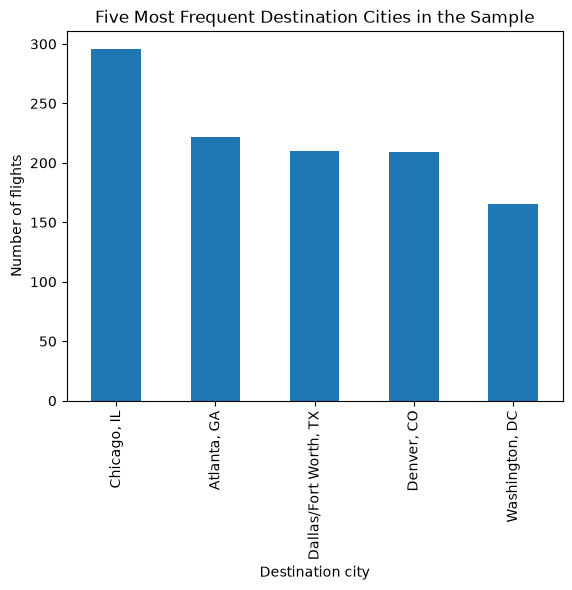

In [13]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


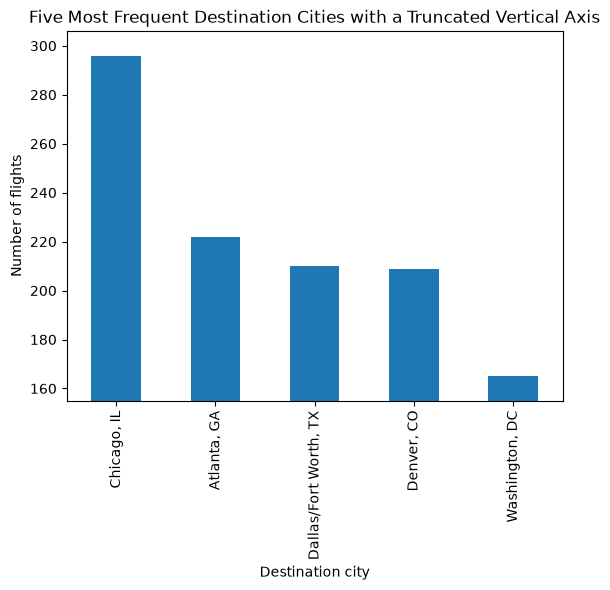

In [14]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer: The truncated axis "shrinks" the range of the y-axis by shifting the starting value of the graph up to make the differences between cities appear much larger than they actually are.


**Which chart communicates the counts more honestly?**

Your answer: The non-truncated graph communicates the differences much more honestly.


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: The month of May 2026


**Which flights were eligible to be included in the sample?**

Your answer: Completed, non-diverted domestic flights with recorded values for all five selected features were eligible


**Which flights and records were excluded before the sample was selected?**

Your answer: Canceled flights, diverted flights, and records missing any selected feature were excluded


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer: No, because incomplete records were removed before the sample was selected


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer: Because those flights were specifically excluded from the sample and therefore none of their data was considered or used in the conclusions found from the sample


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer: A bar chart would be best to use since you can have a single category for each airline on the x-axis while displaying the frequency on the y-axis


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer: A pie chart would be best to show proportion of the sample flights since a pie chart would represent the percentage breakdown for each of the 3 categories to properly show what percentage or proportion each one takes up of the total


**Which chart would you use to show the distribution of flight distances?**

Your answer: A histogram would be best to use since you can break down the flight distances into as many bins as needed to accurately see the distribution and skew of flight distances across flights


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer: 
link to dataset - https://www.kaggle.com/datasets/annisanadhiroh/horror
Title - Horror 
Author - Annisa Nadhiroh
The subject of this data set seems to be famous/well-known horror movies released between 1960 and 2019 but no official description was provided by the author. While the user didn't provide any description of the dataset or create a data dictionary, the page for the dataset has a table showing the dataset contains 100 entries and the table's columns for each entry are name, year, movie_rated, run_length, genres, release_date, rating, num_raters, num_reviewers, and review_url. The years within the year column category range from 1960 to 2019 but there isn't a specific geographic coverage attached to any of the data.


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [15]:
# Load and inspect your chosen dataset here.
horror_df = pd.read_csv("data/Horror.csv")
display(horror_df.head())
display(horror_df.shape)
horror_df.info()
display(horror_df.isnull().sum())

,name,year,movie_rated,run_length,genres,release_date,rating,num_raters,num_reviews,review_url
0,The Shining,1980,R,2h 26min,Drama; Horror;,13 June 1980 (USA),8.4,860290,1805,https://www.imdb.com/title/tt0081505/reviews/_...
1,Alien,1979,R,1h 57min,Horror; Sci-Fi;,22 June 1979 (USA),8.4,762793,1423,https://www.imdb.com/title/tt0078748/reviews/_...
2,World War Z,2013,PG-13,1h 56min,Action; Adventure; Horror;,21 June 2013 (USA),7.0,586801,1125,https://www.imdb.com/title/tt0816711/reviews/_...
3,Psycho,1960,R,1h 49min,Horror; Mystery; Thriller;,8 September 1960 (USA),8.5,580951,1263,https://www.imdb.com/title/tt0054215/reviews/_...
4,Shaun of the Dead,2004,R,1h 39min,Comedy; Horror;,24 September 2004 (USA),7.9,499244,971,https://www.imdb.com/title/tt0365748/reviews/_...


(100, 10)

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          100 non-null    str    
 1   year          100 non-null    int64  
 2   movie_rated   100 non-null    str    
 3   run_length    100 non-null    str    
 4   genres        100 non-null    str    
 5   release_date  100 non-null    str    
 6   rating        100 non-null    float64
 7   num_raters    100 non-null    int64  
 8   num_reviews   100 non-null    int64  
 9   review_url    100 non-null    str    
dtypes: float64(1), int64(3), str(6)
memory usage: 22.0 KB


name            0
year            0
movie_rated     0
run_length      0
genres          0
release_date    0
rating          0
num_raters      0
num_reviews     0
review_url      0
dtype: int64

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
| --- | --- | --- | --- | ---: |
| `name` | N/A | Name Identifier | str | 0 |
| `year` | N/A | Date(Year) | int64 | 0 |
| `movie_rated` | N/A | categorical | str | 0 |
| `run_length` | N/A | Time(Length) | str | 0 |
| `genres` | N/A | categorical | str | 0 |
| `release_date` | N/A | Date | str | 0 |
| `rating` | N/A | quantitative | float64 | 0 |
| `num_raters` | N/A | quantitative | int64 | 0 |
| `num_reviews` | N/A | quantitative | int64 | 0 |
| `review_url` | N/A | Link | str | 0 |






**Missing-value codes or other data preparation, if applicable:**

Your answer: Using isnull().sum() on the dataset returned no missing values. The features didn't come with a data dictionary definition but most are self explanatory with the context of them being used for movies (name for name of movie, genre for genre of movie, run_length for run length of movies, etc.) with the only confusing categories being "movie_rated" which is used to represent the movies age rating while "rating" is used to represent the movies review rating out of 10.


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


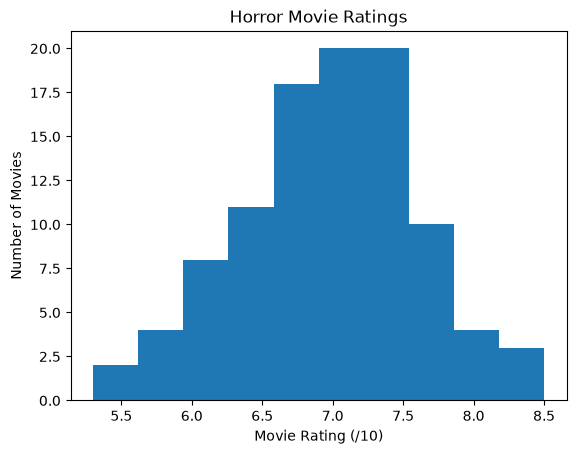

In [16]:
# Create and label your quantitative-feature visualization here.
horror_df["rating"].plot(kind="hist", bins=10)
plt.title("Horror Movie Ratings")
plt.xlabel("Movie Rating (/10)")
plt.ylabel("Number of Movies")
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I chose to chart the "rating" feature using a histogram beacuse for movies, one of the most valuable pieces of data for the average viewer is the rating score of a movie. I also chose to plot using a histogram beacuse a histogram would be best to highlight patterns for a continous quantatative variable and the appearance of the graph would also provide valuable information about the data as a glance.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation: This graph tells me that a majority of the selected horror movies are rated between 6.5 and 7.5 (which typically indicates an "decent" to "good" movie)  since that range along the x-axis captures the 3 bins containing the largest number of movies. This figure also indicates the range of overall ratings being 5.5 to 8.5, while also showing that only a very low amount of movies (below 3) fall into the bins either end of the range.


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


Text(0.5, 1.0, 'Horror Movie Age Ratings')

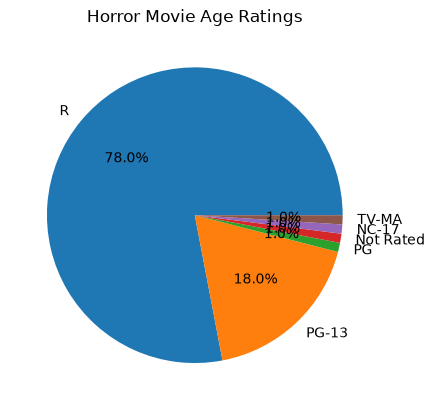

In [17]:
# Create and label your categorical-feature visualization here.
rating_counts= horror_df["movie_rated"].value_counts()
rating_counts.plot.pie(autopct='%1.1f%%')
plt.title("Horror Movie Age Ratings")

**Which feature did you choose, and why is this chart appropriate?**

Your answer: I graphed the "movie_rated" category using a pie chart to visually represent what percentage of movies fall within each rating category

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation: The graph shows that a large majority (78%) of the horror movies from this data-set fall within the "rated R" category as the "pie slice" corresponding to the R rating is much larger than any others. A horror movies being rated as TV-MA (television equivalent of rated R), as NC-17, and not being rated at all aren't uncommon among horror movies but those categories make up the lowest percentage share (1% each) for this dataset. However, the PG rated horror movie also makes an appearance in this data with the same low 1% share, but an actual "horror" movie being rated PG almost never happens. I looked into the dataset and found the movie "Gremlins" was somehow able to get a "PG" rating, which was shocking to me as someone who has seen the movie many times.

## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used: 
- What I asked it to help with: 
- One suggestion I checked against my code, chart, or output:
- What I accepted, modified, or rejected—and why: 

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:
I only used the Google Search built-in AI once but outside of that, if I couldn't find an example from the lecture problems, a simple google search would usually come up with a GeeksforGeeks.com, or a W3Schools.com, or someother tech help website with the anwser I was looking for. For the AI, I asked it how to display every piece of data instead of the top and bottom 5 when printing value_counts, and the suggestion given was to use .to_string() on the variable holding data inside of print(). Since that was a simple and small suggestion, I just tried it out within the code itself and it worked correctly.

## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
